In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.lines import Line2D
from matplotlib.patches import Ellipse
import matplotlib.patches as mpatches
import h5py
import pickle
from scipy.integrate import simpson

In [2]:
def compact_exp_format(num):
    s = "{:.1e}".format(num)  # one decimal place
    base, exp = s.split("e")
    exp = int(exp)
    # Return a string that is already in math mode
    return r"{} \times 10^{{{}}}".format(base, exp)

In [3]:
from feedback_mimic import (
    Mtot_to_MDelta, get_some_quantities, get_spectra, get_realspace_profile, get_NFW_profile, comoving_distance
)

##### Power Spectrum Plots

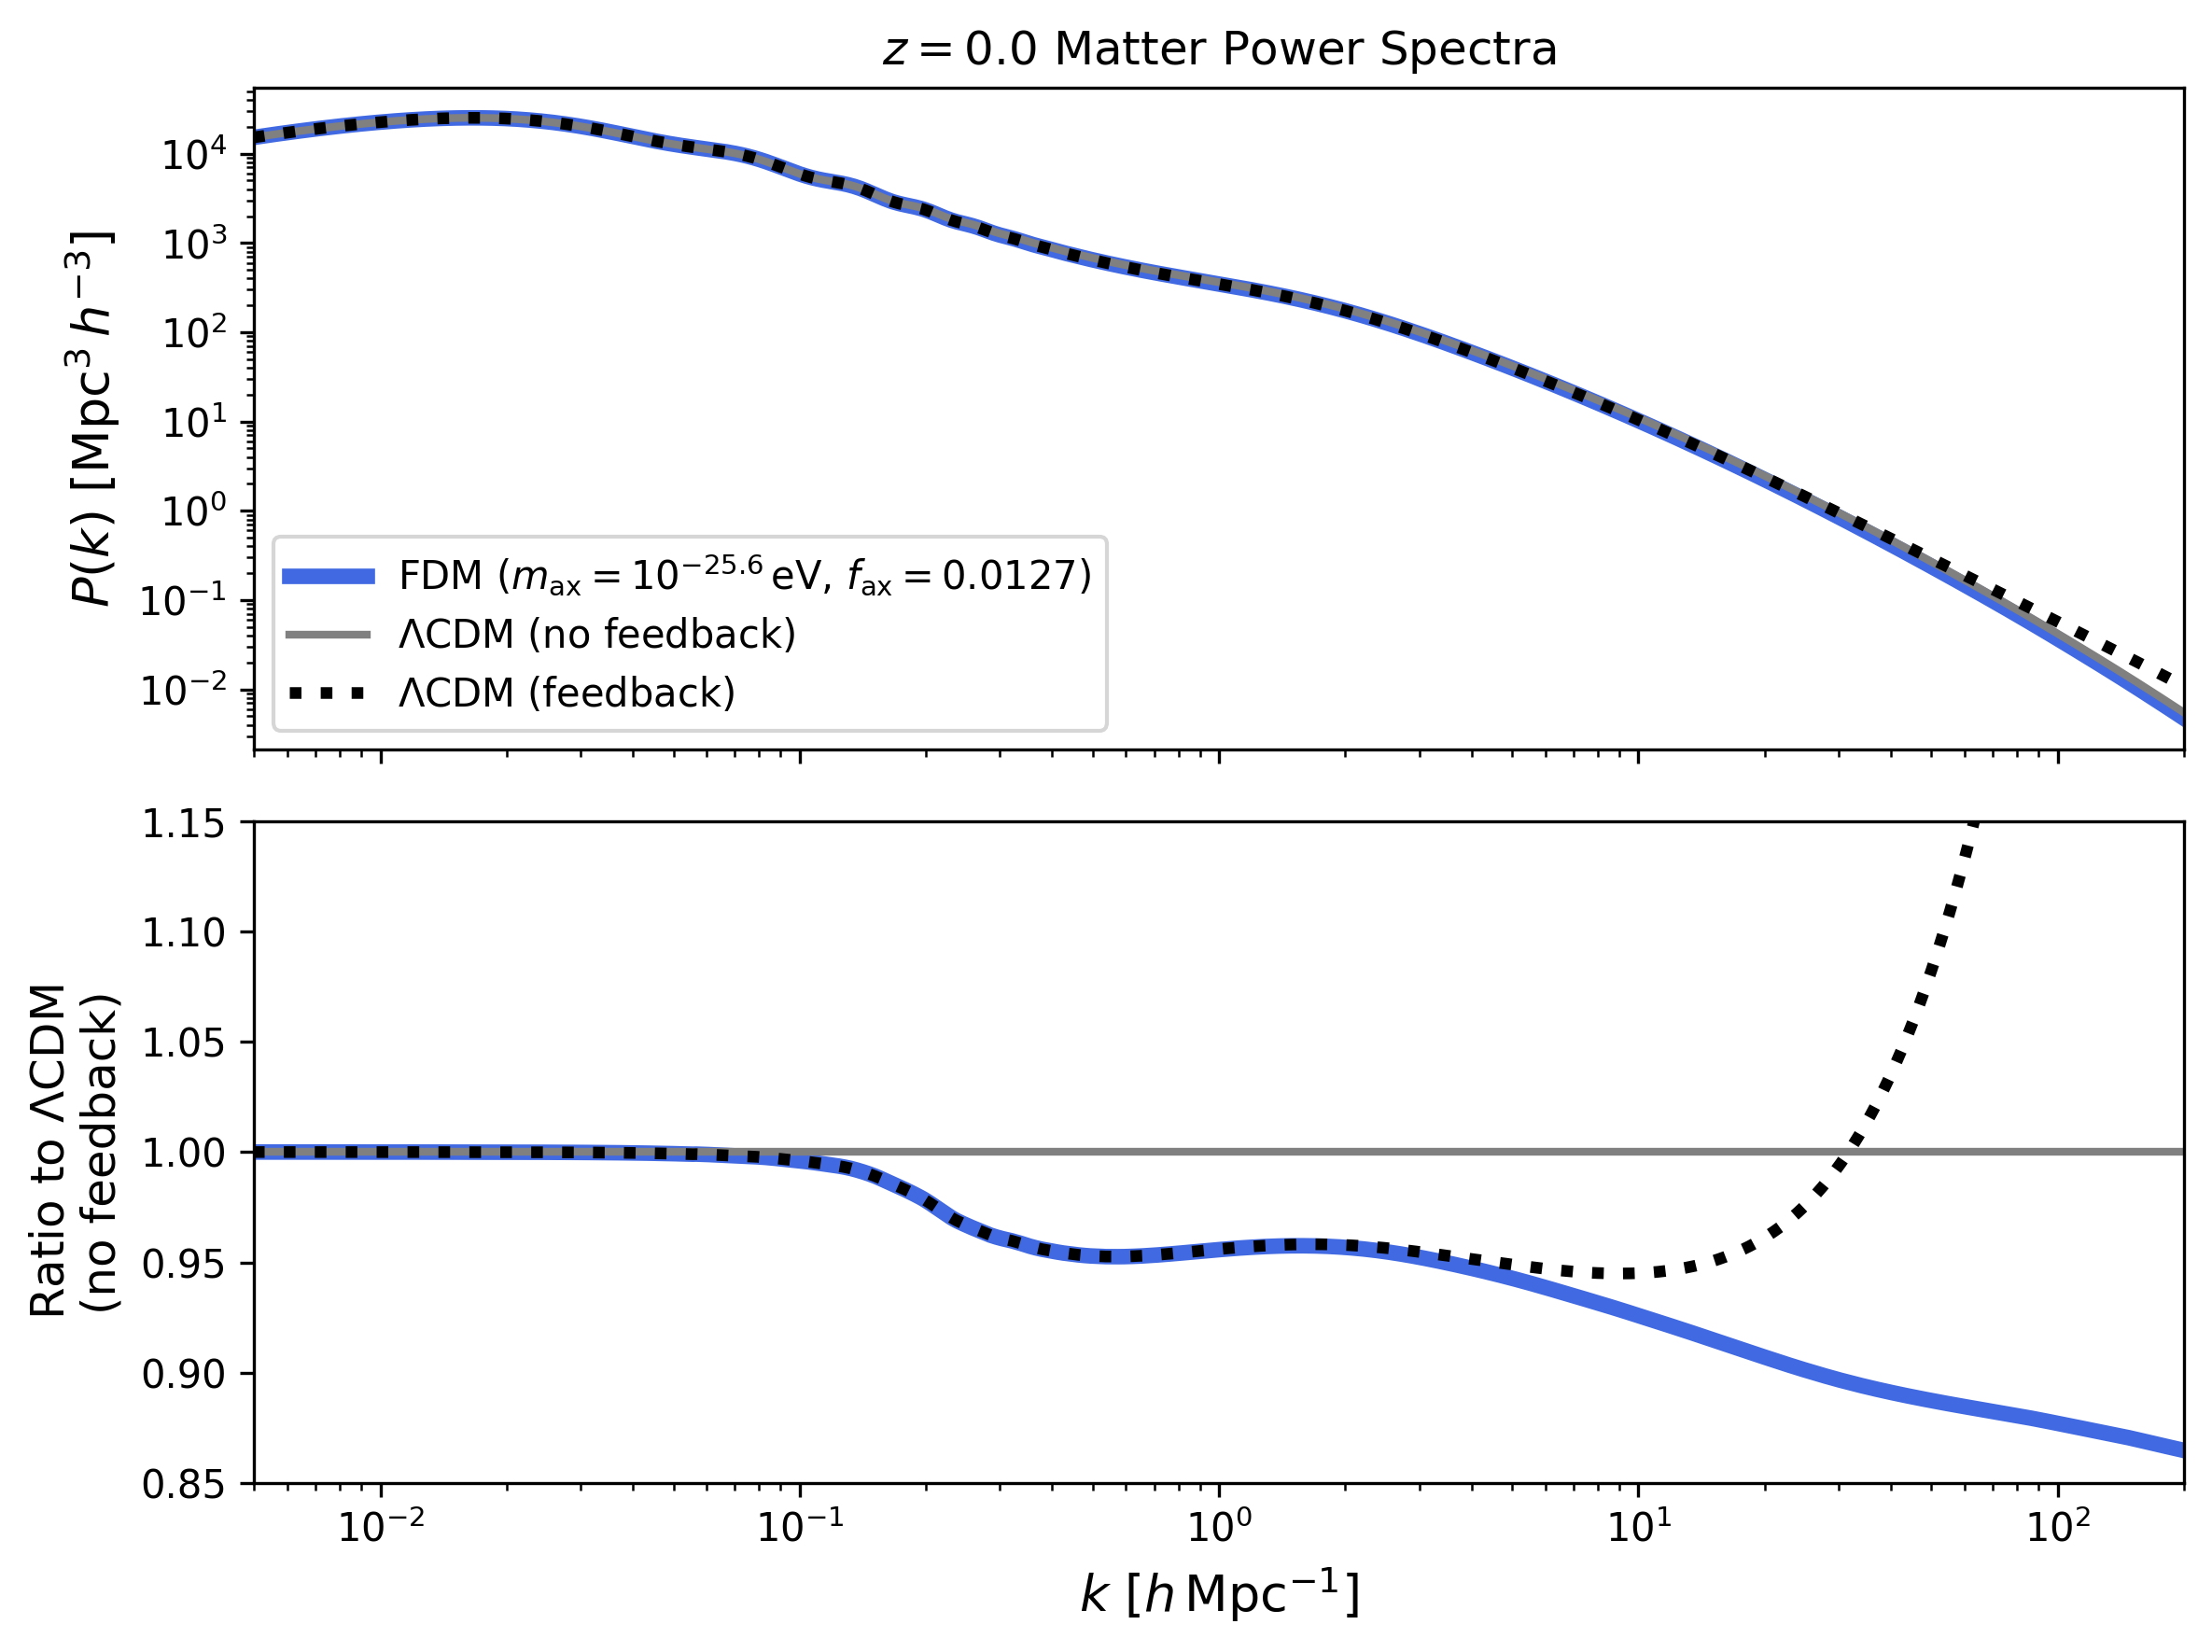

In [4]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), dpi=300, sharex=True, height_ratios=[1.0,1.0])

z = 0.0

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
with open(f"results/halo_model/{z}_data_FDM_full2h_preferred.pkl", "rb") as f:
    data_FDM_preferred = pickle.load(f)

r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
k_arr_HMCode = data_LCDM['power_spec_dic']['k']
M_arr = data_LCDM['M']
K_ARR = np.logspace(-6, 6, 8192)
R_ARR = np.logspace(-4, np.log10(1/min(K_ARR)), 1500)

# FDM preferred
ax1.plot(k_arr_HMCode, data_FDM_preferred['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'],
         c='royalblue', ls='-', lw=4,
         label=r'FDM ($m_\mathrm{ax}=10^{-25.6}\,\mathrm{eV}$, $f_\mathrm{ax}=0.0127$)')
# ΛCDM baseline
ax1.plot(k_arr_HMCode, data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
ax2.plot(k_arr_HMCode, data_LCDM['P'] / data_LCDM['P'],
         c='gray', lw=2, ls='-',
         label=r'$\Lambda$CDM (no feedback)')
# P^target = P_FDM * S_cooling
M200c_arr, r200c_arr = Mtot_to_MDelta(
    data_LCDM, r_v, M_arr, K_ARR, R_ARR, Del=200, reference_density="critical"
)
f_cga = 0.09 * (2.5e11 / M200c_arr)**0.6
R_h   = 0.015 * r200c_arr

u_cga_HMCodek = f_cga[:, None] * np.exp(-(k_arr_HMCode[None, :] * R_h[:, None])**2)
u_cooled = u_cga_HMCodek + (1 - f_cga[:, None]) * data_LCDM['utilde']
u_cooled[M_arr < 2.5e11] = data_LCDM['utilde'][M_arr < 2.5e11]
S_cooling = get_spectra(data_LCDM, u_cooled, full_output=False) / data_LCDM['P']

ax1.plot(k_arr_HMCode, data_FDM_preferred['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')
ax2.plot(k_arr_HMCode, data_FDM_preferred['P'] / data_LCDM['P'] * S_cooling,
         c='k', ls=':', lw=3,
         label=r'$\Lambda$CDM (feedback)')

ax2.set_xlabel(r'$k$ $[h\,\text{Mpc}^{-1}]$', fontsize=13)
ax1.set_ylabel(r'$P(k)$ $[\text{Mpc}^{3}\,h^{-3}]$', fontsize=13)
ax2.set_ylabel(r'Ratio to $\Lambda$CDM' + '\n(no feedback)', fontsize=12)
ax1.set_title(r'$z=0.0$ Matter Power Spectra')
ax2.set_xlim(5e-3, 2e2)
ax2.set_ylim(0.85, 1.15)
ax2.set_xscale('log')
ax1.set_yscale('log')
ax1.legend(loc='lower left')

plt.tight_layout()
plt.show()

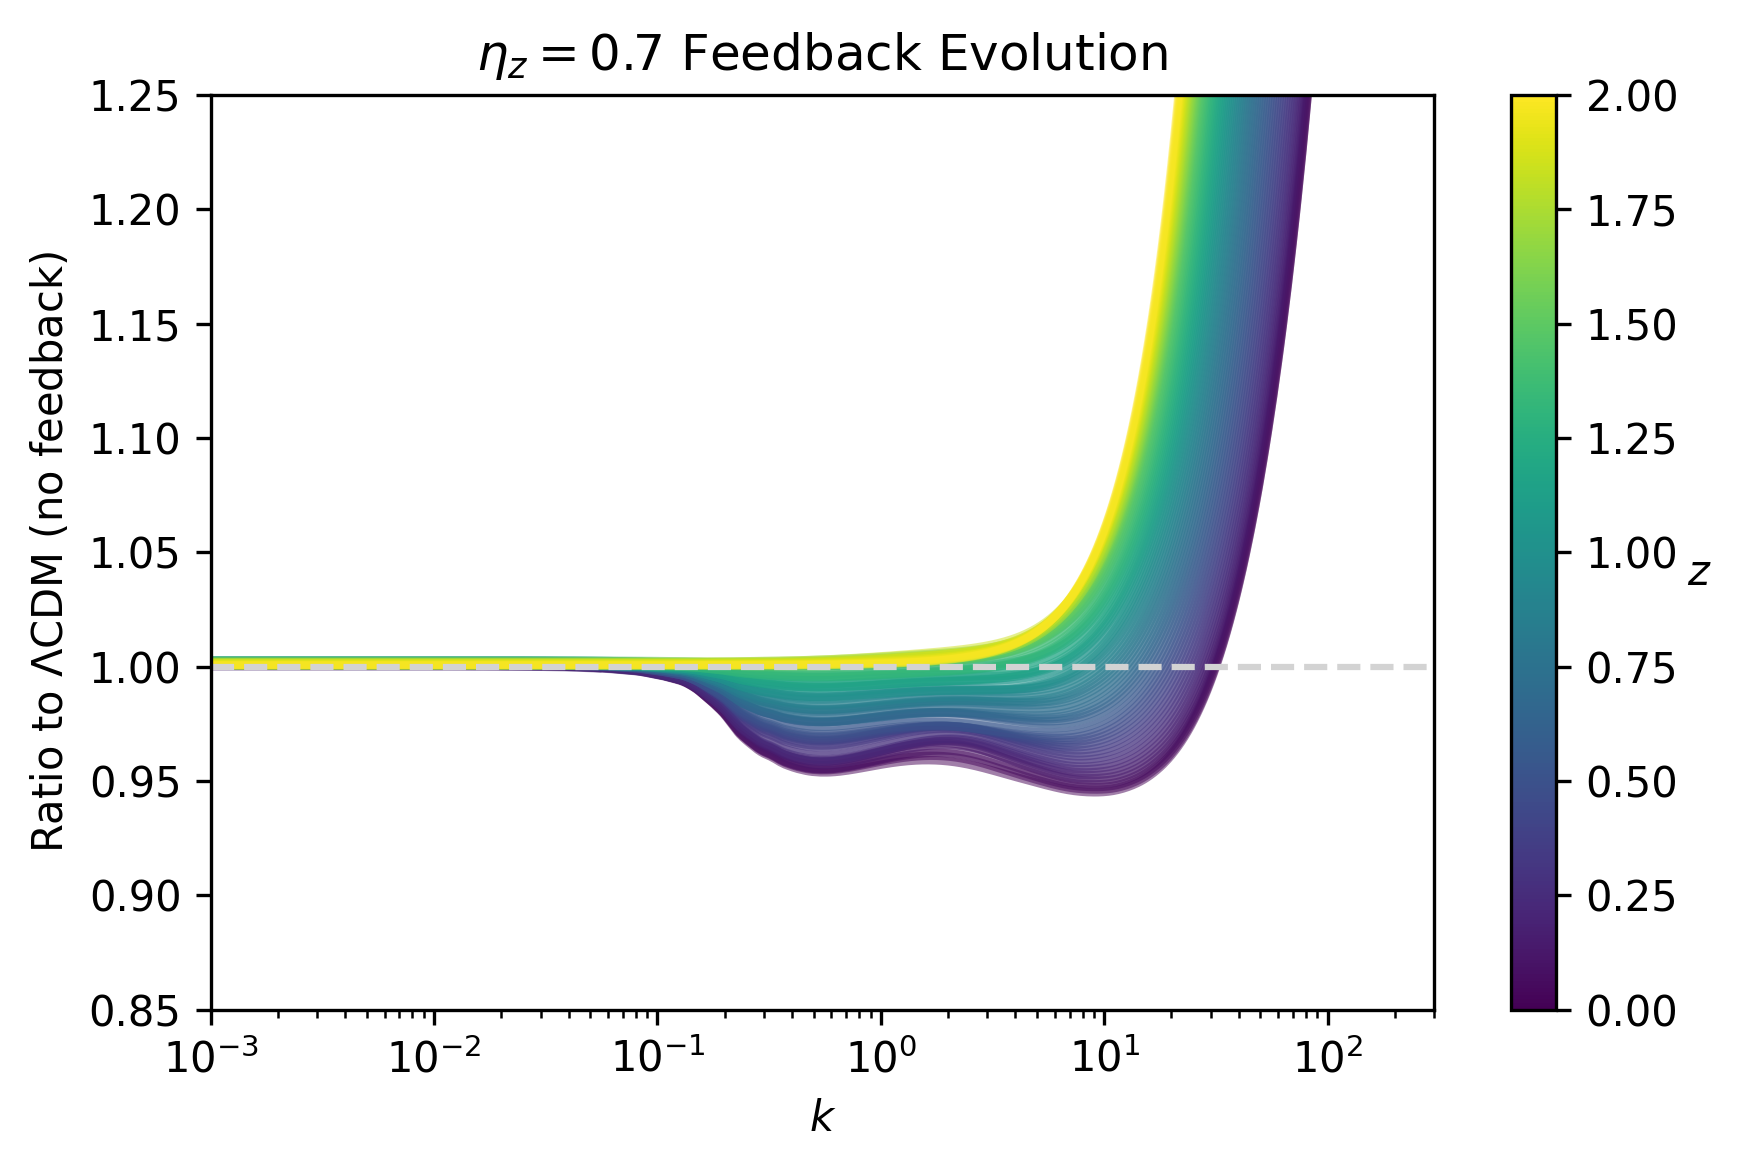

In [5]:
fig, ax1 = plt.subplots(1, 1, figsize=(6, 4), dpi=300)

gamma_val = 0.0
etaz = 0.7

K_ARR  = np.logspace(-6, 6, 8192)
R_ARR  = np.logspace(-4, np.log10(1 / K_ARR.min()), 1500)

z_arr      = np.linspace(0.0, 2.0, 81)
#z_arr = [0.0,0.5,1.0,1.5,2.0]
cmap = plt.cm.viridis
colors = cmap(np.linspace(0, 1, len(z_arr)))

for z, color in zip(z_arr, colors):
    with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
        data_LCDM = pickle.load(f)
    k_arr_HMCode = data_LCDM['power_spec_dic']['k']

    feedback_model = f"etaz{etaz}_preferred_cooled"
    baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
    #baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]

    ax1.semilogx(k_arr_HMCode, baryonic_profile[-1]['P']/data_LCDM['P'], c=color, ls='-',lw=2.,alpha=0.5)

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=0.0, vmax=2.0))
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax1)
cbar.set_label(r'$z$', rotation=0, labelpad=5)

ax1.axhline(1.0, c='lightgray', ls='--')

ax1.set_xlabel(r'$k$')
ax1.set_ylabel(r'Ratio to $\Lambda$CDM (no feedback)')

ax1.set_ylim(0.85,1.25)
ax1.set_xlim(1e-3,3e2)
ax1.set_title(fr"$\eta_z = {etaz}$ Feedback Evolution")

plt.tight_layout()
plt.show()

##### Profile Plots

/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")
/tmp/ipykernel_2645470/3895193278.py:30: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
/tmp/ipykernel_2645470/3895193278.py:33: RuntimeWarning: invalid value encountered in divide
  ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])


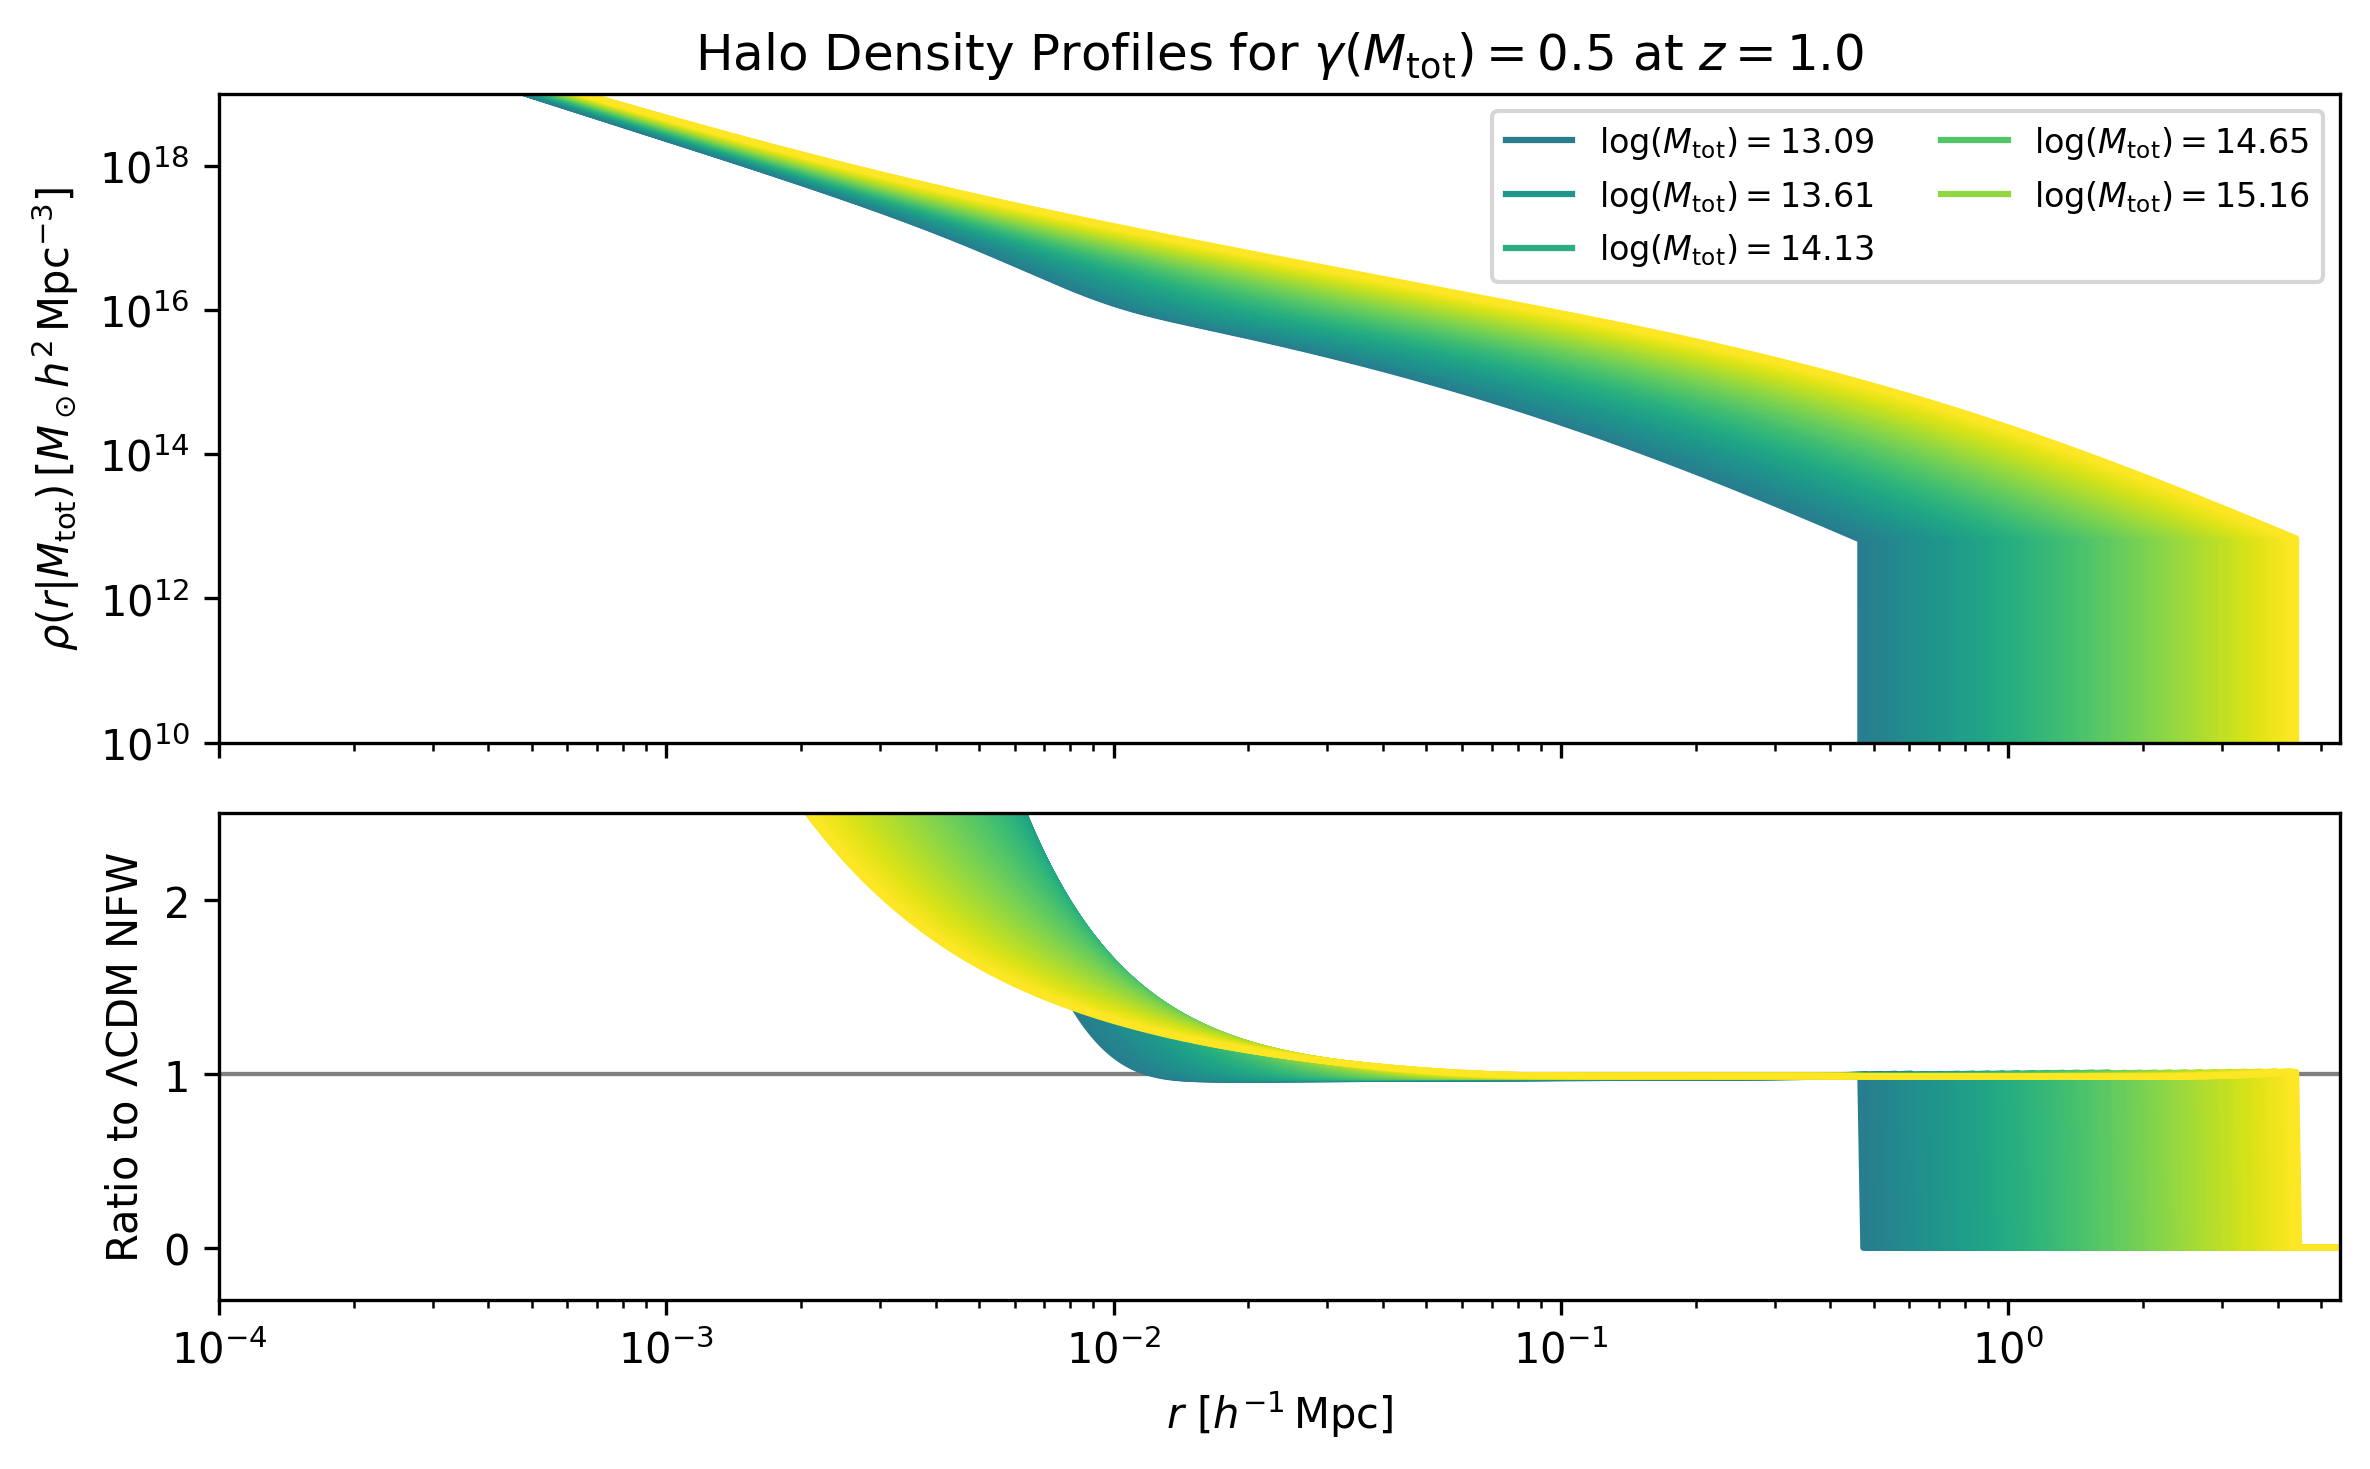

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 5), dpi=300, sharex=True, gridspec_kw={'height_ratios': [2, 1.5]})

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)
k_arr = np.logspace(-6, 6, 8192)
r_arr = np.logspace(-4, np.log10(1/min(k_arr)), 1500)

gamma_val = 0.5
etaz = 0.7
z = 1.0
feedback_model = f"etaz{etaz}_preferred_cooled"
keys = np.arange(np.size(data_LCDM['M'])) # M values
keys_labels = [0,31,62,93,125,156,187,218,249] # M values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))

ax2.axhline(1, color='gray', linestyle='-', linewidth=1)

with open(f"results/halo_model/{z}_data_LCDM_full2h_preferred.pkl", "rb") as f:
    data_LCDM = pickle.load(f)
r_v, rho_crit, rho_char, concentration, r_s, Delta_vir, rho_0, rho_0_wh = get_some_quantities(data_LCDM)
rho_NFW = get_realspace_profile(get_NFW_profile(k_arr=k_arr, r_s=r_s, r_v=r_v, r_t=max(r_arr) * r_v/r_v), 
                                r_t=max(r_arr) * r_v/r_v, r_arr=r_arr, k_arr=k_arr, M_arr=data_LCDM['M'])

#baryonic_profile = np.load(f"results/feedback_models/{feedback_model}/utilde_results_gamma{gamma_val}_z{z}.npy",allow_pickle=True)[()]
baryonic_profile = np.load(f"results/profile_matching/{feedback_model}/utilde_results_gamma{gamma_val}_25it_z{z}.npy",allow_pickle=True)[()]
for m_index in keys[125:]:
    if m_index in keys_labels:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]), label=r"$\log(M_\text{tot}) = $" + str(np.round(np.log10(data_LCDM['M'][m_index]),2)),c=color_dict[m_index])
    else:
        ax1.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index]),c=color_dict[m_index])
        ax2.plot(r_arr, (baryonic_profile[-1]['rho_hat_unbiased'][m_index])/(rho_NFW[m_index]),c=color_dict[m_index])
#print(np.round(baryonic_profile[-1]['M_total_enclosed']/M_arr,4))

ax1.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
ax2.set_xlim(1e-4, max([r_v[m_index],baryonic_profile[-1]['r_t_unbiased'][m_index]])*1.25)
#ax2.set_ylim(0.5,1.5)
#ax1.set_ylim(1e12,1e19)
ax2.set_ylim(-0.3,2.5)
ax1.set_ylim(1e10,1e19)

ax2.set_ylabel(r'Ratio to $\Lambda$CDM NFW')
ax2.set_xscale("log")
ax2.set_yscale("linear")
ax1.set_yscale("log")
ax1.set_ylabel(r'$\rho(r|M_\text{tot}) \, [M_\odot h^2\,\text{Mpc}^{-3} ]$')
ax2.set_xlabel(r'$r$ $[h^{-1}\,\text{Mpc}]$')

ax1.set_title(rf'Halo Density Profiles for $\gamma(M_\text{{tot}}) = {gamma_val}$ at $z={z}$')
ax1.legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()

##### Cluster Counts Plot

LCDM_hat0.0: N_sel=25622
LCDM_hat0.5: N_sel=25868
LCDM_hat1.0: N_sel=26188
LCDM: N_sel=28396
FDM_preferred: N_sel=27133


/tmp/ipykernel_2645470/184373450.py:391: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


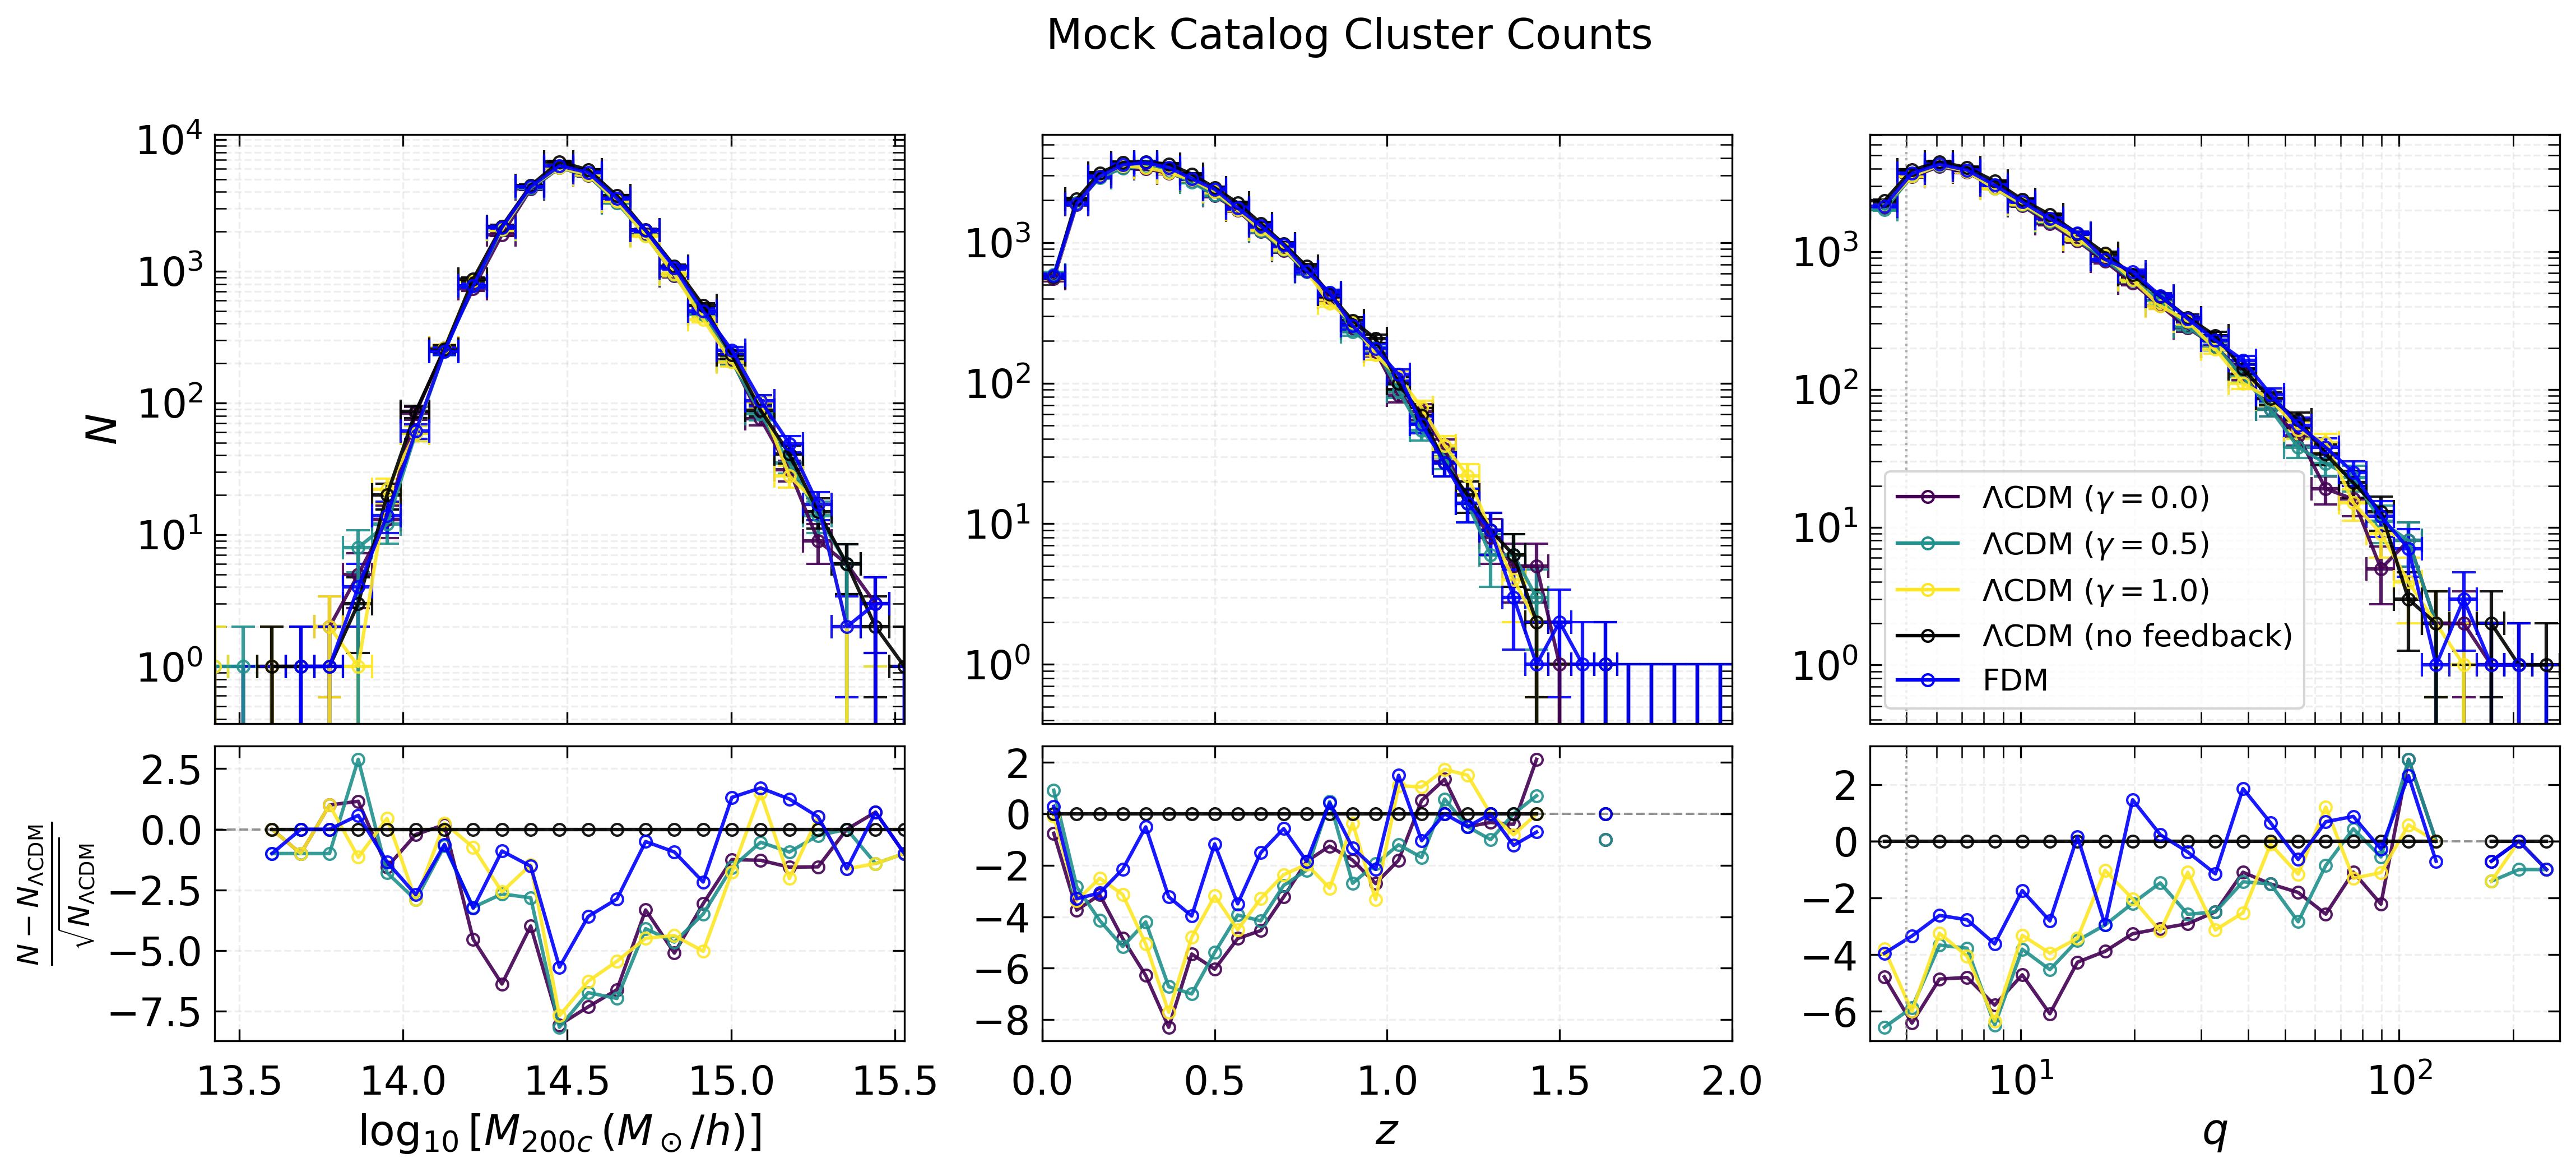

In [7]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ──────────────────────────────────────────────────────────────────────────────
# CONFIG
# ──────────────────────────────────────────────────────────────────────────────

CATALOG_DIR = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs"
SEED = 42

keys = [0.0,0.5,1.0] # gamma values
cmap = plt.get_cmap('viridis')
colors = [cmap(i / (len(keys)-1)) for i in range(len(keys))]
color_dict = dict(zip(keys, colors))
HMF_TYPES = [
    'LCDM_hat0.0',
    'LCDM_hat0.5',
    'LCDM_hat1.0',
    'LCDM',
    'FDM_preferred',
]

COLORS = [
    color_dict[0.0],
    color_dict[0.5],
    color_dict[1.0],
    'k',
    'b',
]

LABELS = [
    r'$\Lambda$CDM ($\gamma=0.0$)',
    r'$\Lambda$CDM ($\gamma=0.5$)',
    r'$\Lambda$CDM ($\gamma=1.0$)',
    r'$\Lambda$CDM (no feedback)',
    r'FDM',
]

N_BINS_M = 25
N_BINS_Z = 30
N_BINS_Q = 25

label_size = 17
title_size = 18
legend_size = 13

q_type = 'q_true'

# ──────────────────────────────────────────────────────────────────────────────
# STYLING
# ──────────────────────────────────────────────────────────────────────────────

def style_ax(ax):

    ax.tick_params(
        axis='x',
        which='both',
        length=5,
        direction='in',
        pad=10
    )

    ax.tick_params(
        axis='y',
        which='both',
        length=5,
        direction='in',
        pad=5
    )

    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')

    plt.setp(
        ax.get_yticklabels(),
        rotation='horizontal',
        fontsize=label_size
    )

    plt.setp(
        ax.get_xticklabels(),
        fontsize=label_size
    )

    ax.grid(
        visible=True,
        which='both',
        alpha=0.2,
        linestyle='--'
    )


# ──────────────────────────────────────────────────────────────────────────────
# LOAD CATALOGS
# ──────────────────────────────────────────────────────────────────────────────

cats = {}

for hmf_type in HMF_TYPES:

    path = (
        f"{CATALOG_DIR}/"
        f"{hmf_type.replace('.', 'p')}_mock_seed{SEED}.pkl"
    )

    with open(path, "rb") as f:
        cats[hmf_type] = pickle.load(f)

    print(f"{hmf_type}: N_sel={cats[hmf_type]['n_selected']}")

# ──────────────────────────────────────────────────────────────────────────────
# BINNING
# ──────────────────────────────────────────────────────────────────────────────

ref = cats['LCDM']

M_edges = np.logspace(
    np.log10(ref['M200c_true'].min() * 0.6),
    np.log10(ref['M200c_true'].max() * 1.1),
    N_BINS_M + 1
)

z_edges = np.linspace(
    0.0,
    2.0,
    N_BINS_Z + 1
)

q_edges = np.logspace(
    np.log10(ref['Q_TH'] * 0.8),
    np.log10(ref[q_type].max() * 1.1),
    N_BINS_Q + 1
)

M_centres = 0.5 * (M_edges[1:] + M_edges[:-1])
z_centres = 0.5 * (z_edges[1:] + z_edges[:-1])
q_centres = 0.5 * (q_edges[1:] + q_edges[:-1])

# plotting coordinates

M_x = np.log10(M_centres)
z_x = z_centres
q_x = q_centres

# ──────────────────────────────────────────────────────────────────────────────
# HORIZONTAL BIN-WIDTH ERRORS
# ──────────────────────────────────────────────────────────────────────────────

M_xerr = np.vstack([
    M_x - np.log10(M_edges[:-1]),
    np.log10(M_edges[1:]) - M_x
])

z_xerr = np.vstack([
    z_x - z_edges[:-1],
    z_edges[1:] - z_x
])

q_xerr = np.vstack([
    q_x - q_edges[:-1],
    q_edges[1:] - q_x
])

# ──────────────────────────────────────────────────────────────────────────────
# HISTOGRAMS
# ──────────────────────────────────────────────────────────────────────────────

counts = {}

for hmf_type in HMF_TYPES:

    c = cats[hmf_type]

    counts[hmf_type] = {
        'M': np.histogram(c['M200c_true'], bins=M_edges)[0].astype(float),
        'z': np.histogram(c['z'], bins=z_edges)[0].astype(float),
        'q': np.histogram(c[q_type], bins=q_edges)[0].astype(float),
    }

n_lcdm = counts['LCDM']

# ──────────────────────────────────────────────────────────────────────────────
# FIGURE
# ──────────────────────────────────────────────────────────────────────────────

fig, axes = plt.subplots(
    2,
    3,
    figsize=(18, 7),
    dpi=300,
    gridspec_kw={
        'height_ratios': [1, 0.5],
        'hspace': 0.05,
    }
)

(ax_M, ax_z, ax_q), (ax_dM, ax_dz, ax_dq) = axes

top_axes = [ax_M, ax_z, ax_q]
bot_axes = [ax_dM, ax_dz, ax_dq]

# ──────────────────────────────────────────────────────────────────────────────
# PLOTTING
# ──────────────────────────────────────────────────────────────────────────────

for hmf_type, color, label in zip(HMF_TYPES, COLORS, LABELS):

    n = counts[hmf_type]

    # -------------------------------------------------------------------------
    # TOP ROW
    # -------------------------------------------------------------------------

    for ax, vals, x, xerr in [

        (ax_M, n['M'], M_x, M_xerr),
        (ax_z, n['z'], z_x, z_xerr),
        (ax_q, n['q'], q_x, q_xerr),

    ]:

        ax.errorbar(
            x,
            vals,
            xerr=xerr,
            yerr=np.sqrt(np.maximum(vals, 1)),
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            capsize=5,
            color=color,
            alpha=0.9,
            label=label
        )

    # -------------------------------------------------------------------------
    # BOTTOM ROW
    # -------------------------------------------------------------------------

    for ax, vals, ref_vals, x in [

        (ax_dM, n['M'], n_lcdm['M'], M_x),
        (ax_dz, n['z'], n_lcdm['z'], z_x),
        (ax_dq, n['q'], n_lcdm['q'], q_x),

    ]:

        safe_ref = np.where(ref_vals > 0, ref_vals, np.nan)

        delta_sigma = (vals - ref_vals) / np.sqrt(safe_ref)

        ax.plot(
            x,
            delta_sigma,
            marker='o',
            markersize=5,
            fillstyle='none',
            ls='-',
            lw=1.5,
            color=color,
            alpha=0.9,
        )

# ──────────────────────────────────────────────────────────────────────────────
# TOP ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in top_axes:

    style_ax(ax)

    ax.set_yscale('log')

    ax.tick_params(
        labelbottom=False
    )

top_axes[0].set_ylabel(
        r'$N$',
        size=title_size
    )

# q axis

ax_q.set_xscale('log')

ax_q.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# BOTTOM ROW FORMATTING
# ──────────────────────────────────────────────────────────────────────────────

for ax in bot_axes:

    style_ax(ax)

    ax.axhline(
        0,
        color='k',
        lw=1,
        ls='--',
        alpha=0.4
    )

bot_axes[0].set_ylabel(
    r'$\frac{N-N_{\Lambda\rm CDM}}{\sqrt{N_{\Lambda\rm CDM}}}$',
    size=title_size
)

ax_dM.set_xlabel(
    r'$\log_{10}[M_{200c}\,(M_\odot/h)]$',
    size=title_size
)

ax_dz.set_xlabel(
    r'$z$',
    size=title_size
)

ax_dq.set_xlabel(
    r'$q$',
    size=title_size
)

ax_dq.set_xscale('log')

ax_dq.axvline(
    ref['Q_TH'],
    color='gray',
    lw=1,
    ls=':',
    alpha=0.6
)

# ──────────────────────────────────────────────────────────────────────────────
# AXIS LIMITS
# ──────────────────────────────────────────────────────────────────────────────

ax_M.set_xlim(M_x.min(), M_x.max())
ax_dM.set_xlim(M_x.min(), M_x.max())

ax_z.set_xlim(z_edges[0], z_edges[-1])
ax_dz.set_xlim(z_edges[0], z_edges[-1])

ax_q.set_xlim(q_edges[0], q_edges[-1])
ax_dq.set_xlim(q_edges[0], q_edges[-1])

# optional redshift ticks

ax_M.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_dM.set_xticks([13.5,14.0,14.5,15.0,15.5])
ax_z.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])
ax_dz.set_xticks([0.0, 0.5, 1.0, 1.5, 2.0])

# ──────────────────────────────────────────────────────────────────────────────
# LEGEND
# ──────────────────────────────────────────────────────────────────────────────

handles = [
    Line2D(
        [0],
        [0],
        color=c,
        lw=1.5,
        marker='o',
        markersize=5,
        fillstyle='none',
        label=l
    )
    for c, l in zip(COLORS, LABELS)
]

ax_q.legend(
    handles=handles,
    loc='lower left',
    frameon=True,
    fontsize=legend_size
)

plt.suptitle("Mock Catalog Cluster Counts", fontsize=title_size)
plt.tight_layout()
plt.show()

##### MCMC Plot

In [8]:
import pickle
import numpy as np
import os
import cosmocnc_axionHMcode_jax.cosmocnc_jax as cosmocnc
from wl_likelihoods import log_lik_wl_all
from cosmocnc_axionHMcode_jax.cosmocnc_jax.hmf import (
    func_axionHMcode_D_z_unnorm_int,
    func_axionHMcode_D_z_unnorm)
from astropy.cosmology import FlatLambdaCDM

h_fid       = 0.68
omega_b_fid = 0.0226576
ns_fid      = 0.965
omega_m_fid = 0.143344
logAs_fid   = np.log(2.1e-09 * 1e10)

INCLUDE_SHEAR_LIKELIHOOD = False
_SURVEY_SR  = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/surveys/survey_sr_so_sim.py"
_SURVEY_WL  = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/surveys/survey_wl_so_sim.py"
_SURVEY_CAT = "/home/jange/scratch/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/surveys/survey_cat_so_sim.py"

Z_ARR        = np.linspace(0.0, 2.0, 81)
Z_ARR = Z_ARR[Z_ARR > 0]

defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/
defaulting to  /rds-d4/user/iz221/hpc-work/cosmopower/
defaulting to  /scratch/scratch-jange/cosmocnc_axionHMcode_jax/cosmocnc_jax/


In [9]:
# Precompute a bunch of quantities so we dont have to do it on the fly, and can just interpolate
_astropy_cosmo_fid = FlatLambdaCDM(H0=h_fid*100., Om0=omega_m_fid/h_fid**2)
_omega_m_grid      = np.linspace(0.05, 0.30, 50)
_Om0_grid          = _omega_m_grid / h_fid**2
_z_table           = np.concatenate([np.linspace(1e-6, 1., 500), np.linspace(1., 100., 500)])
_z_source_bins     = np.array([0.285, 0.476, 0.743, 0.942])

_G_SI    = 6.674e-11
_c_SI    = 2.998e8
_Mpc_m   = 3.0857e22
_Msol_kg = 1.989e30

_cache_path = "/home/jange/scratch/FeedbackMimic/results/mcmc/MCMC_GRID_CACHE.pkl"
if os.path.exists(_cache_path):
    with open(_cache_path, "rb") as f:
        _G_a_grid, _D_table, _norm_grid, _DA_table, _Sigma_crit_table = pickle.load(f)
    print("Loaded precomputed tables from cache")
else:
    print("Precomputing tables (one-time cost)...")
    _G_a_grid  = np.array([
        func_axionHMcode_D_z_unnorm_int(
            0., Om0,
            lambda z, c=FlatLambdaCDM(H0=h_fid*100., Om0=Om0): c.H(z).value/(h_fid*100.))
        for Om0 in _Om0_grid])
    _norm_grid = np.array([
    func_axionHMcode_D_z_unnorm(
        0., Om0,
        lambda z, c=FlatLambdaCDM(H0=h_fid*100., Om0=Om0): c.H(z).value/(h_fid*100.))
    for Om0 in _Om0_grid])
    _D_table = np.zeros((len(_omega_m_grid), len(_z_table)))
    for i, Om0 in enumerate(_Om0_grid):
        cosmo_i = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        E_z_i   = lambda z, c=cosmo_i: c.H(z).value / (h_fid * 100.)
        norm_i  = _norm_grid[i]
        _D_table[i] = [func_axionHMcode_D_z_unnorm(z, Om0, E_z_i) / norm_i
                       for z in _z_table]
    _DA_table = np.zeros((len(_omega_m_grid), len(Z_ARR)))
    for i, Om0 in enumerate(_Om0_grid):
        for j, z in enumerate(Z_ARR):
            _DA_table[i, j] = comoving_distance(
                {"cosmos": {"z": z, "h": h_fid,
                             "Omega_m_0": Om0, "Omega_w_0": 1.-Om0}}, z) / (1+z)
    _Sigma_crit_table = np.zeros((len(_omega_m_grid), len(Z_ARR)))
    for i, Om0 in enumerate(_Om0_grid):
        cosmo_i = FlatLambdaCDM(H0=h_fid*100., Om0=Om0)
        for j, z in enumerate(Z_ARR):
            usable = _z_source_bins[_z_source_bins > z]
            if len(usable) == 0:
                _Sigma_crit_table[i, j] = np.inf
                continue
            inv_scs = []
            for z_s in usable:
                DA_s  = cosmo_i.angular_diameter_distance(z_s).value
                DA_ls = cosmo_i.angular_diameter_distance_z1z2(z, z_s).value
                if DA_ls <= 0:
                    continue
                inv_sc = (4.*np.pi*_G_SI/_c_SI**2
                          * _DA_table[i,j]*_Mpc_m * DA_ls*_Mpc_m / (DA_s*_Mpc_m))
                inv_scs.append(inv_sc * _Msol_kg / _Mpc_m**2)
            _Sigma_crit_table[i, j] = 1./np.mean(inv_scs) if inv_scs else np.inf
    with open(_cache_path, "wb") as f:
        pickle.dump((_G_a_grid, _D_table, _norm_grid, _DA_table, _Sigma_crit_table), f)
    print("Saved tables")


def _interp_omega_m(omega_m, table):
    """Linear interpolation over the omega_m grid."""
    w    = np.interp(omega_m/h_fid**2, _Om0_grid, np.arange(len(_Om0_grid), dtype=float))
    i_lo = int(np.clip(np.floor(w), 0, len(_Om0_grid)-2))
    frac = w - i_lo
    return (1.-frac)*table[i_lo] + frac*table[i_lo+1]

def get_G_a_interp(omega_m):        return np.interp(omega_m, _omega_m_grid, _G_a_grid)
def get_norm_interp(omega_m):       return np.interp(omega_m, _omega_m_grid, _norm_grid)
def get_D_grid_interp(omega_m):     return _z_table.copy(), _interp_omega_m(omega_m, _D_table)
def get_DA_grid_interp(omega_m):    return Z_ARR.copy(),    _interp_omega_m(omega_m, _DA_table)
def get_Sigma_crit_arr(omega_m):    return _interp_omega_m(omega_m, _Sigma_crit_table)

Loaded precomputed tables from cache


In [10]:
# one nc object per catalogue, initialised lazily
_nc_cache = {}

def _get_nc(catalogue_name):
    if catalogue_name not in _nc_cache:
        nc = cosmocnc.cluster_number_counts()
        nc.cnc_params.update({
            "survey_sr"                : _SURVEY_SR,
            "survey_cat"               : _SURVEY_CAT,
            "obs_select"               : "q_so_sim",
            "observables"              : [["q_so_sim"]],
            "obs_select_min"           : 5.0,
            "obs_select_max"           : 200.0,
            "z_min"                    : Z_ARR[0],
            "z_max"                    : Z_ARR[-1],
            "M_min"                    : 1e13 / h_fid,
            "M_max"                    : 1e16 / h_fid,
            "cluster_catalogue"        : catalogue_name,
            "likelihood_type"          : "unbinned",
            "data_lik_from_abundance"  : False,
            "scalrel_type_deriv"       : "analytical",
            "n_points"                 : 1000,
            "n_z"                      : len(Z_ARR),
            "cosmology_tool"           : "classy_sz_jax",
            "power_spectrum_type"      : "cosmopower",
            "cosmo_amplitude_parameter": "A_s",
            "hmf_calc"                 : "cnc",
            "hmf_type"                 : "ST_axionHMcode",
            "mass_definition"          : "200c",
            "number_cores_hmf"         : 1,
            "number_cores_abundance"   : 1,
            "number_cores_data"        : 1,
            "cosmocnc_verbose"         : "none",
            "return_profile_params"    : True,
        })
        nc.initialise()
        _nc_cache[catalogue_name] = nc
    return _nc_cache[catalogue_name]


def get_log_likelihood(
    catalogue_name,
    # ── free parameters ──
    omega_m  = omega_m_fid,
    logAs    = logAs_fid,
    A_sz     = -4.3054,
    alpha_sz = 1.1233,
    beta_sz  = 2.0,
    b_WL_0    = 0.0, 
    b_WL_M    = 1.0,
    # ── fixed ────────────
    bias_sz       = 0.8,
    sigma_lnq     = 0.173,
    dof           = 0.0,
    q_cutoff      = 0.0,
    M_WL_pivot    = 2e14, # Msol/h
    wl_catalogue = None,
    sigma_shape = 0.37,
    n_source    = 5.5  # arcmin^-2
):
    """
    Returns  ln L = -N_bar + sum_i ln P(q_obs,i, z_i | params).
    First call per catalogue_name runs initialise() (slow).
    Subsequent calls only run reinitialise() (fast).
    """
    nc = _get_nc(catalogue_name)
    z_table, D_grid = get_D_grid_interp(omega_m)

    nc.cosmo_params.update({
        "Om0"     : omega_m / h_fid**2,
        "Ob0"     : omega_b_fid / h_fid**2,
        "h"       : h_fid,
        "A_s"     : np.exp(logAs) * 1e-10,
        "n_s"     : ns_fid,
        "m_nu"    : 0.06,
        "tau_reio": 0.0544,
        "n_mass_points_coarse": 50,
        # ── These are necessary to make ST_axionHMcode fast ──
        "G_a_precomputed":           get_G_a_interp(omega_m),
        "D_grid_z_precomputed":      z_table,
        "D_grid_precomputed":        D_grid,
        "normalisation_precomputed": get_norm_interp(omega_m),
        "Sigma_crit_vec": get_Sigma_crit_arr(omega_m)
    })
    nc.scal_rel_params.update({
        "A_szifi"        : A_sz,
        "alpha_szifi"    : alpha_sz,
        "beta_szifi"     : beta_sz,
        "bias_sz"        : bias_sz,
        "sigma_lnq_szifi": sigma_lnq,
        "dof"            : dof,
        "q_cutoff"       : q_cutoff,
    })

    try:
        nc.reinitialise()
        nc.get_hmf(return_profile_params=True)
        log_lik_sz = nc.get_log_lik()
        # After nc.get_log_lik() runs, check the components
        nc.get_number_counts()
        print(f"N_tot predicted: {float(nc.n_tot):.1f}")  # should be ~O(1000), not crazy
    except Exception as e:
        print(f"cosmocnc_jax failed: {e}")
        return -np.inf

    if INCLUDE_SHEAR_LIKELIHOOD and wl_catalogue is not None:
        # Posterior mean lnM from the SZ backward convolution
        n_wl = wl_catalogue
        bc_cpdf  = np.asarray(nc.bc_cpdf_array)
        bc_lnM   = np.asarray(nc.bc_lnM_array)
        lnM_means = np.array([
            np.trapezoid(bc_lnM[p] * bc_cpdf[p], bc_lnM[p]) /
            np.maximum(np.trapezoid(bc_cpdf[p], bc_lnM[p]), 1e-300)
            for p in np.asarray(nc.bc_cluster_indices)
        ])
        z_wl = np.asarray(nc.bc_z_clusters)
        
        # NFW profile params at posterior mass, from cosmocnc's profile_params
        profile = nc.get_profile_params_at_clusters(z_wl, lnM_means)
    
        # Sigma_crit per cluster from precomputed table (omega_m-dependent)
        Sigma_crit_all = get_Sigma_crit_arr(omega_m)   # (n_z,) on Z_ARR
        Sigma_crit_wl = np.interp(z_wl, Z_ARR, Sigma_crit_all)

        A_ann = 2*np.pi*R_arr*dR*(180*60/np.pi/DA_arr[iz])**2  # arcmin² per bin
        sigma_g = sigma_shape / np.sqrt(np.maximum(n_source*A_ann, 1.))
    
        log_liks_wl = log_lik_wl_all(
            jnp.array(wl_catalogue["shear_profiles"]),
            jnp.array(sigma_g),
            jnp.array(wl_catalogue["R_proj_arr"]),
            jnp.array(profile['r_s']),
            jnp.array(profile['delta_char']),
            jnp.full(wl_catalogue['n_selected'], profile['rho_m']),
            jnp.array(Sigma_crit_wl),
            float(b_WL_0),
            float(b_WL_M),
            jnp.array(jnp.exp(lnM_means)*1e14*h_fid), # M_200c means, Msol/h
            M_WL_pivot,                               # Msol/h
            64,
        )
    
        return float(log_lik_sz) + float(jnp.sum(log_liks_wl))
    return float(log_lik_sz)

In [12]:
catalogue_name = "/home/jange/scratch/FeedbackMimic/results/mock_catalogs/LCDM_mock_seed42.pkl"

with open(catalogue_name, "rb") as f:
    catalogue = pickle.load(f)

ln_L = get_log_likelihood(
    catalogue_name = catalogue_name,
    omega_m  = 0.143344,
    logAs    = np.log(2.1e-09 * 1e10),
    A_sz     = -4.3054,
    alpha_sz = 1.1233,
    beta_sz = 2.,
    b_WL_0  = 0.,
    b_WL_M  = 1.,
    wl_catalogue = catalogue
)
ln_L

PATH_TO_CLASS_SZ_DATA not set. Setting it now...
Defaulting to: /home/jange/class_sz_data_directory


2026-06-09 17:05:21.980256: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected
/scratch/scratch-jange/FeedbackMimic/cosmocnc_axionHMcode_jax/cosmocnc_jax/cnc.py:782: DeprecationWarning: compute_class_szfast is deprecated. Use initialize_classy_szfast instead.
  self.cosmology = cosmology_model(cosmo_params=self.cosmo_params,
/home/jange/jange_env/lib/python3.12/site-packages/mcfit/mcfit.py:130: UserWarning: use backend='jax' if desired
  warnings.warn("use backend='jax' if desired")


N_tot predicted: 36376.1


187427.54854145483